# T18 策略参数比较与推荐

> 负责人：胡馨澜（代号 D）· 优先级 P0 · 交付物：比较结果 + 推荐配置，记入 `decisions.md`
> 生成日期：2026-11-08
> 数据基础：`evidence/eval_log.jsonl`，共 6,568 次真实 `solver.exe` 调用（95 个阶段，2026-11-06 17:44 至 2026-11-08 18:24）
> 说明：标注「建议」的参数为待与 T15/T12 对齐后定稿，其余为实测结论。


## 1. 结论

1. **推荐配置已确定**：三栋楼各自 4 个非零槽位（合计 12 个非零），F5/F6 主导、精确零权重、行和归一化到 1；实测 **R = 104.851733**（eval_id 6335）。
2. **在线提议应以「选支持集」为主、数值微调为辅**：支持集结构决定 R 的量级，支持集确定后只在每栋楼的 F5/F6 比例 `r = w5/(w5+w6)` 上做一维扫描即可。
3. **不推荐**：跨 21 维随机搜索、用 `1e-9` 替代零权重、步长小于 0.0025 的反复精扫。


## 2. 推荐配置（实测最优，可直接复现）

| 楼栋 | F1 | F2 | F3 | F4 | F5 | F6 | F7 | 行和 | `r = F5/(F5+F6)` |
|---|---|---|---|---|---|---|---|---|---|
| 楼1 | 0.0 | 0.045 | 0.0 | 0.0 | 0.257993 | 0.687007 | 0.010 | 1.0 | 0.27301 |
| 楼2 | 0.0 | 0.010 | 0.0 | 0.0 | 0.210690 | 0.649270 | 0.130040 | 1.0 | 0.24500 |
| 楼3 | 0.0 | 0.0 | 0.010 | 0.0 | 0.246351 | 0.733645 | 0.010004 | 1.0 | 0.25138 |

- 非零槽位：楼1 = {F2, F5, F6, F7}；楼2 = {F2, F5, F6, F7}；楼3 = {F3, F5, F6, F7}。
- F5+F6 占比：楼1 94.5%、楼2 86.0%、楼3 98.0%，三栋平均 92.8%。
- 权重文件：`best_weights_phaseE5.json`（`best_R = 104.85173345124349`，`eval_id = 6335`，`label = "S6 楼3 r=0.25138"`）。


In [ ]:
import json

with open("evidence/best_weights_phaseE5.json", encoding="utf-8") as f:
    bw = json.load(f)

print("best_R =", bw["best_R"], "| eval_id =", bw["eval_id"], "| label =", bw["label"])
for i, row in enumerate(bw["weights_by_building"], 1):
    nz = [j + 1 for j, v in enumerate(row) if v > 0]
    share = (row[4] + row[5]) / sum(row)
    print("楼%d: 非零槽位=%s 行和=%.6f F5+F6占比=%.4f" % (i, nz, sum(row), share))


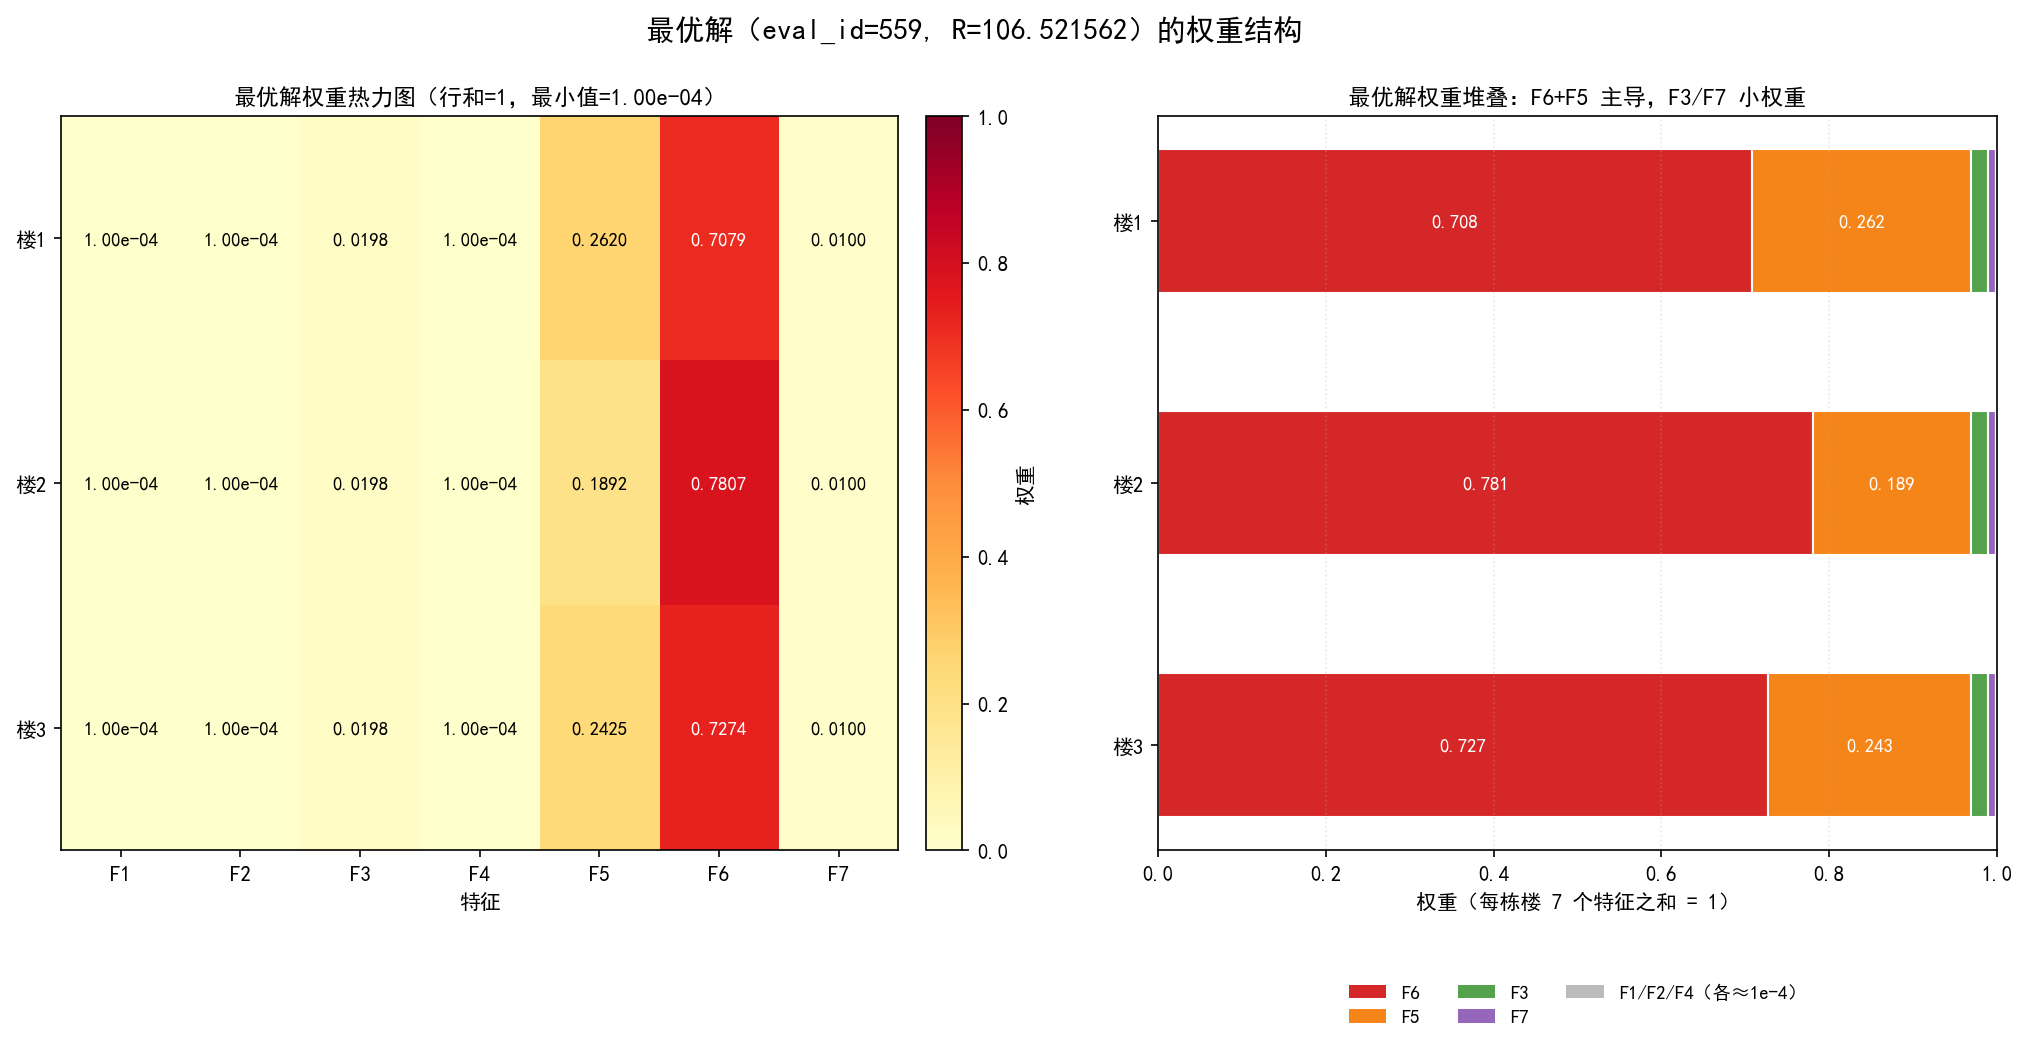

In [ ]:
from IPython.display import Image, display
display(Image(filename="figures/fig_all_best_structure.png"))


## 3. 策略族比较（全部为实测）

| 策略族 | 样本数 | 最好 R | 说明 |
|---|---|---|---|
| 21 维均匀/随机（screen） | 44 | 124.595 | 无结构先验，最好也只到 124.6 |
| 单特征顶点（vertex） | 343 | 120.299 | 只扫单特征顶点无法进入平台 |
| 全正随机撒点（vE5_Q1R） | 120 | 109.443 | 盲随机覆盖全稀疏度谱 |
| 结构化 5 非零（Q1A–Q1D） | 31 | 108.909 | 5 非零固定支持集 |
| 5 非零 + 迁移（Q1E） | 12 | 105.542 | 加入 F3 迁移后进入 105 区间 |
| 同构支持集（同特征集跨楼） | 55 组 | 107.836 | 三栋楼共用同一支持集的上限 |
| **异构支持集 + 一维细扫（最终）** | 49 | **104.852** | 三栋楼各自选支持集 |


## 4. 支持集规模与最好 R（全量 6,568 点）

| 非零槽位数 | 样本数 | 最好 R |
|---|---|---|
| 3 | 1 | 117.802 |
| 6 | 225 | 106.944 |
| 9 | 475 | 105.535 |
| 11 | 285 | 105.074 |
| **12** | **1,291** | **104.852** |
| 13 | 231 | 105.118 |
| 16 | 364 | 106.079 |
| 21（全正） | 1,626 | 105.940 |

结论：12 个非零是当前最优结构；再多（13–18）反而变差，说明不是「非零越多越好」，而是「槽位选对 + 其余精确为 0」。


In [ ]:
import collections

rows = [json.loads(line) for line in open("evidence/eval_log.jsonl", encoding="utf-8") if line.strip()]
print("总评估次数 =", len(rows))

by_nz = collections.defaultdict(list)
for r in rows:
    by_nz[sum(1 for w in r["weights"] if w > 0)].append(r["R"])
for k in sorted(by_nz):
    print("非零=%2d  n=%4d  best=%.3f" % (k, len(by_nz[k]), min(by_nz[k])))


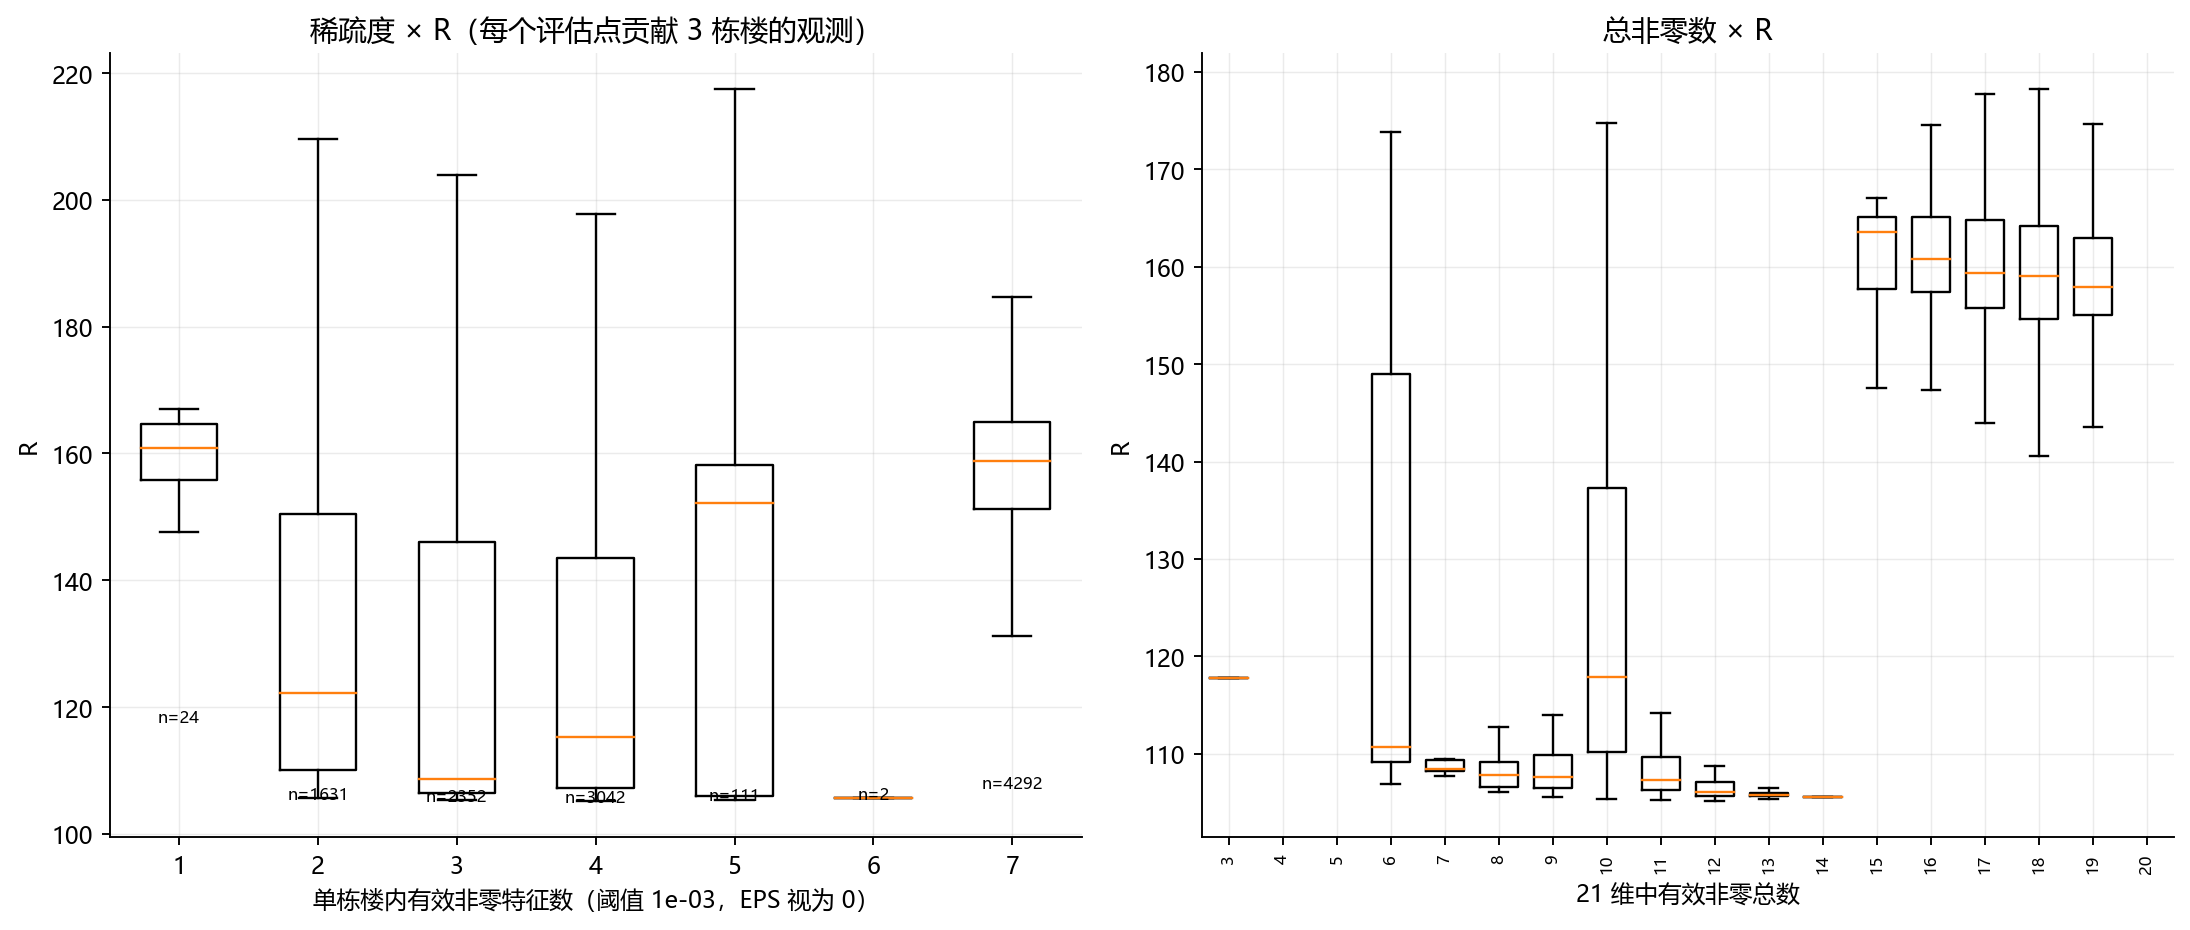

In [ ]:
from IPython.display import Image, display
display(Image(filename="figures/e2_sparsity_R.png"))


## 5. 步长/扫描方式比较（实测）

| 阶段 | 方式 | 步长 | 最好 R |
|---|---|---|---|
| E3 地形粗扫（vE3_G） | 大范围格点 | 0.20 | 109.456 |
| E4 一维细线（scans 1–3） | `r` 单变量扫描 | 0.00125 | 104.852 |
| E5 量化边界（Q3A/Q4） | 边界二分 | 0.00002 | 104.852（未再改进） |

- 平台宽度实测约 **7×10⁻⁴**（权重单位），边界定位精度 ±2×10⁻⁵；换算到 `r` 约 7.4×10⁻⁴。
- 6,568 次评估中 R<105 仅 33 次，R<104、R<103、R<100 均为 **0 次**。


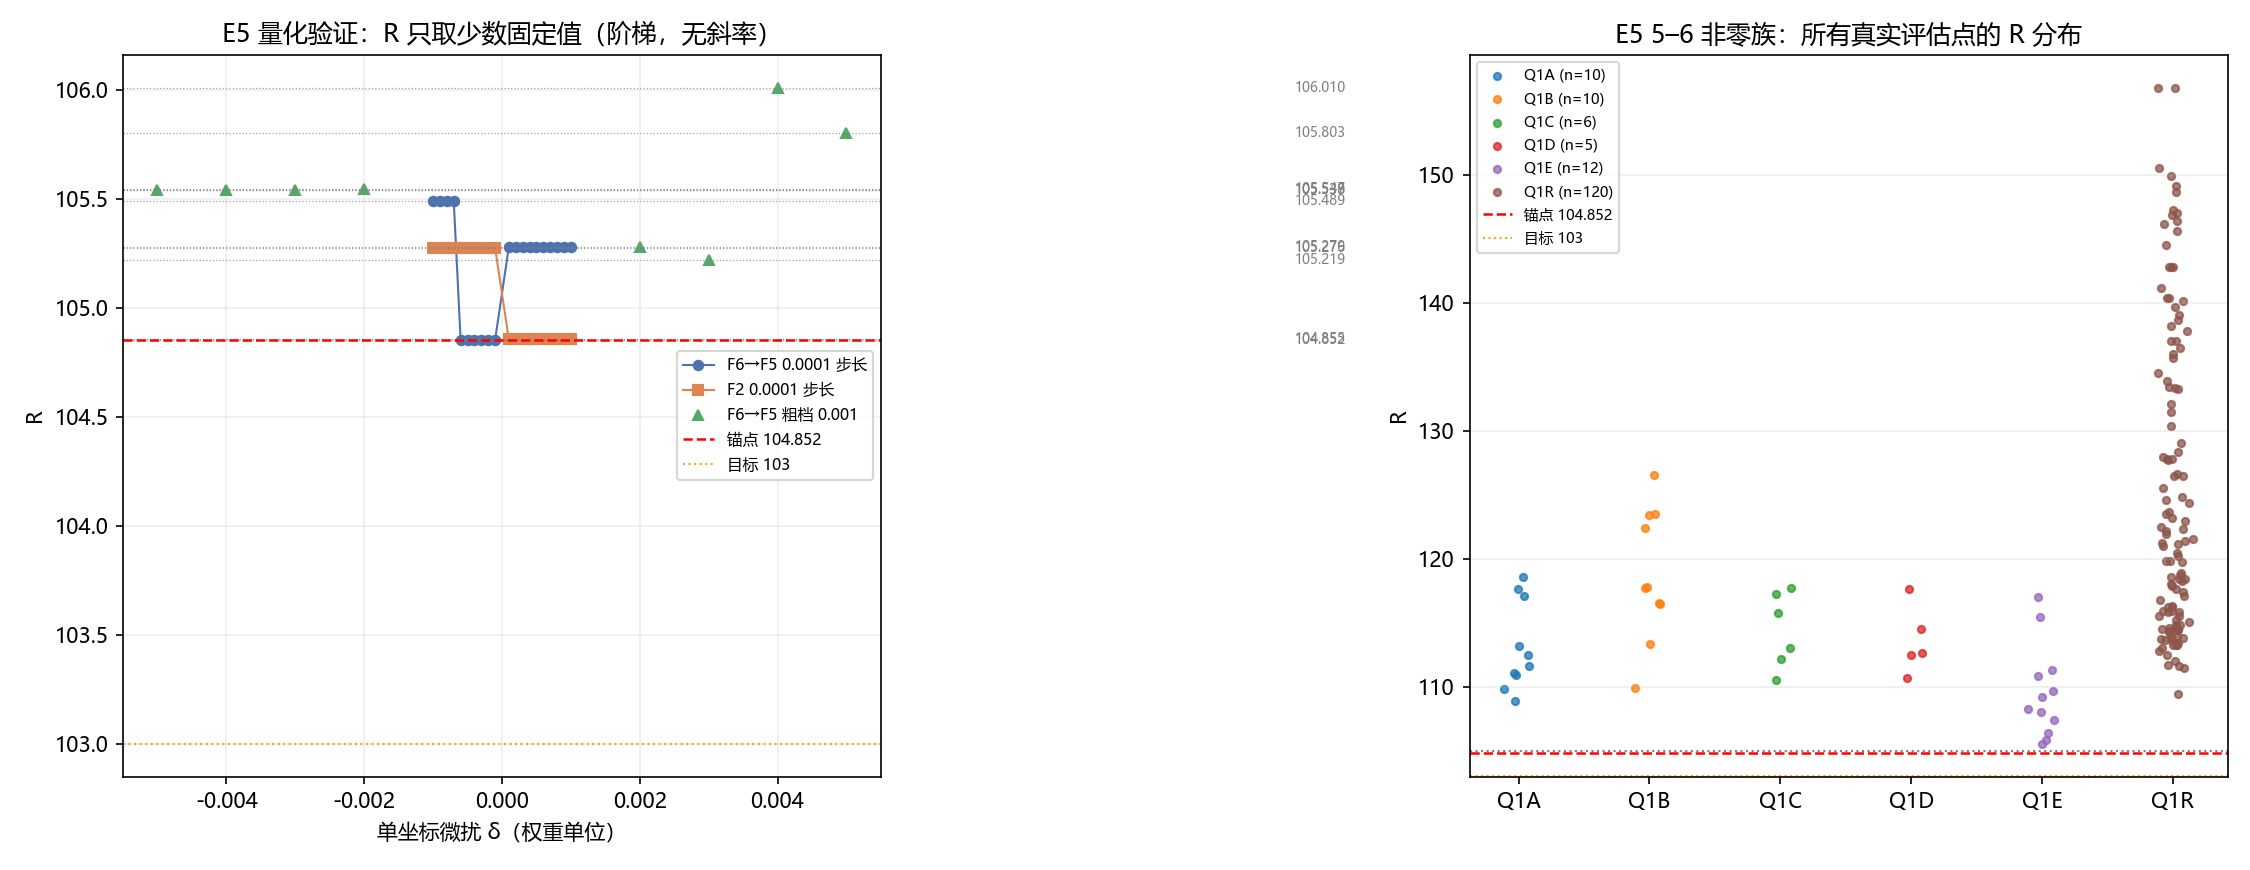

In [ ]:
from IPython.display import Image, display
display(Image(filename="figures/e14_e5_quantization.png"))


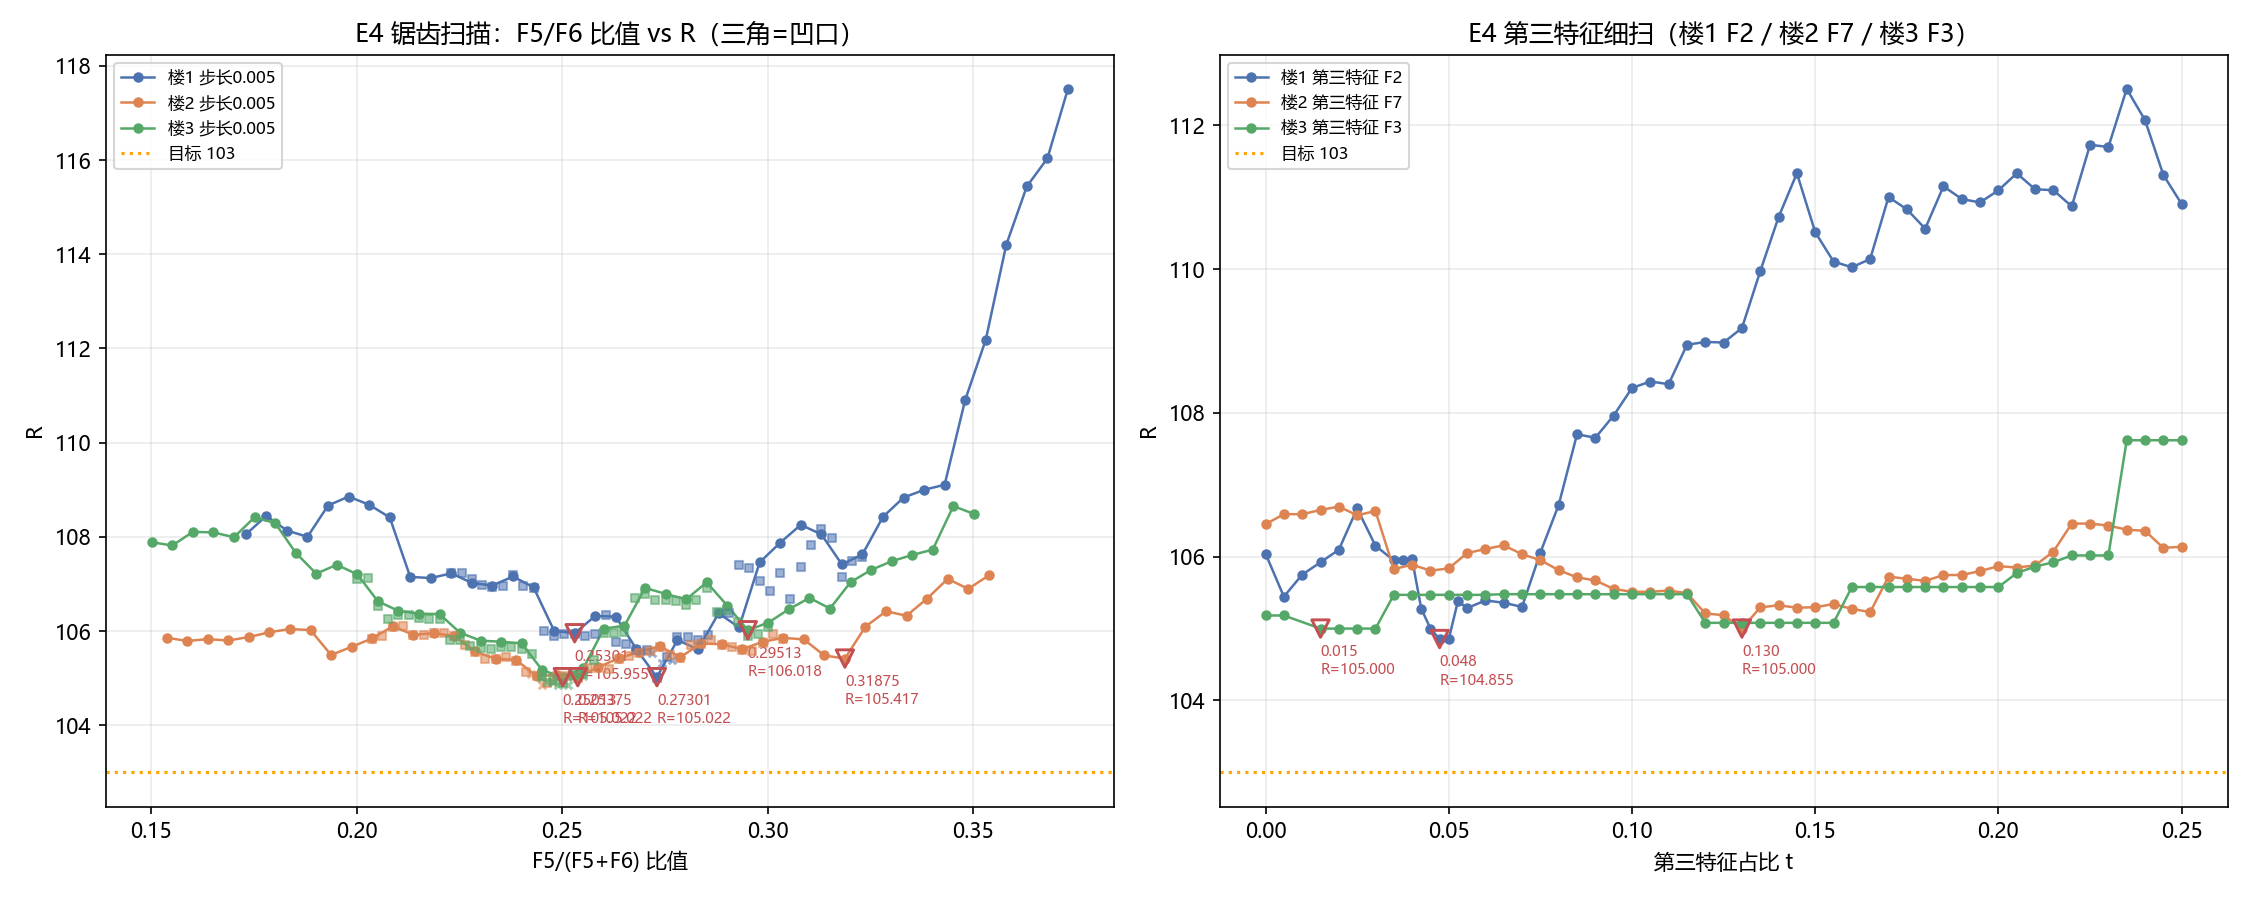

In [ ]:
from IPython.display import Image, display
display(Image(filename="figures/e13_e4_sawtooth.png"))


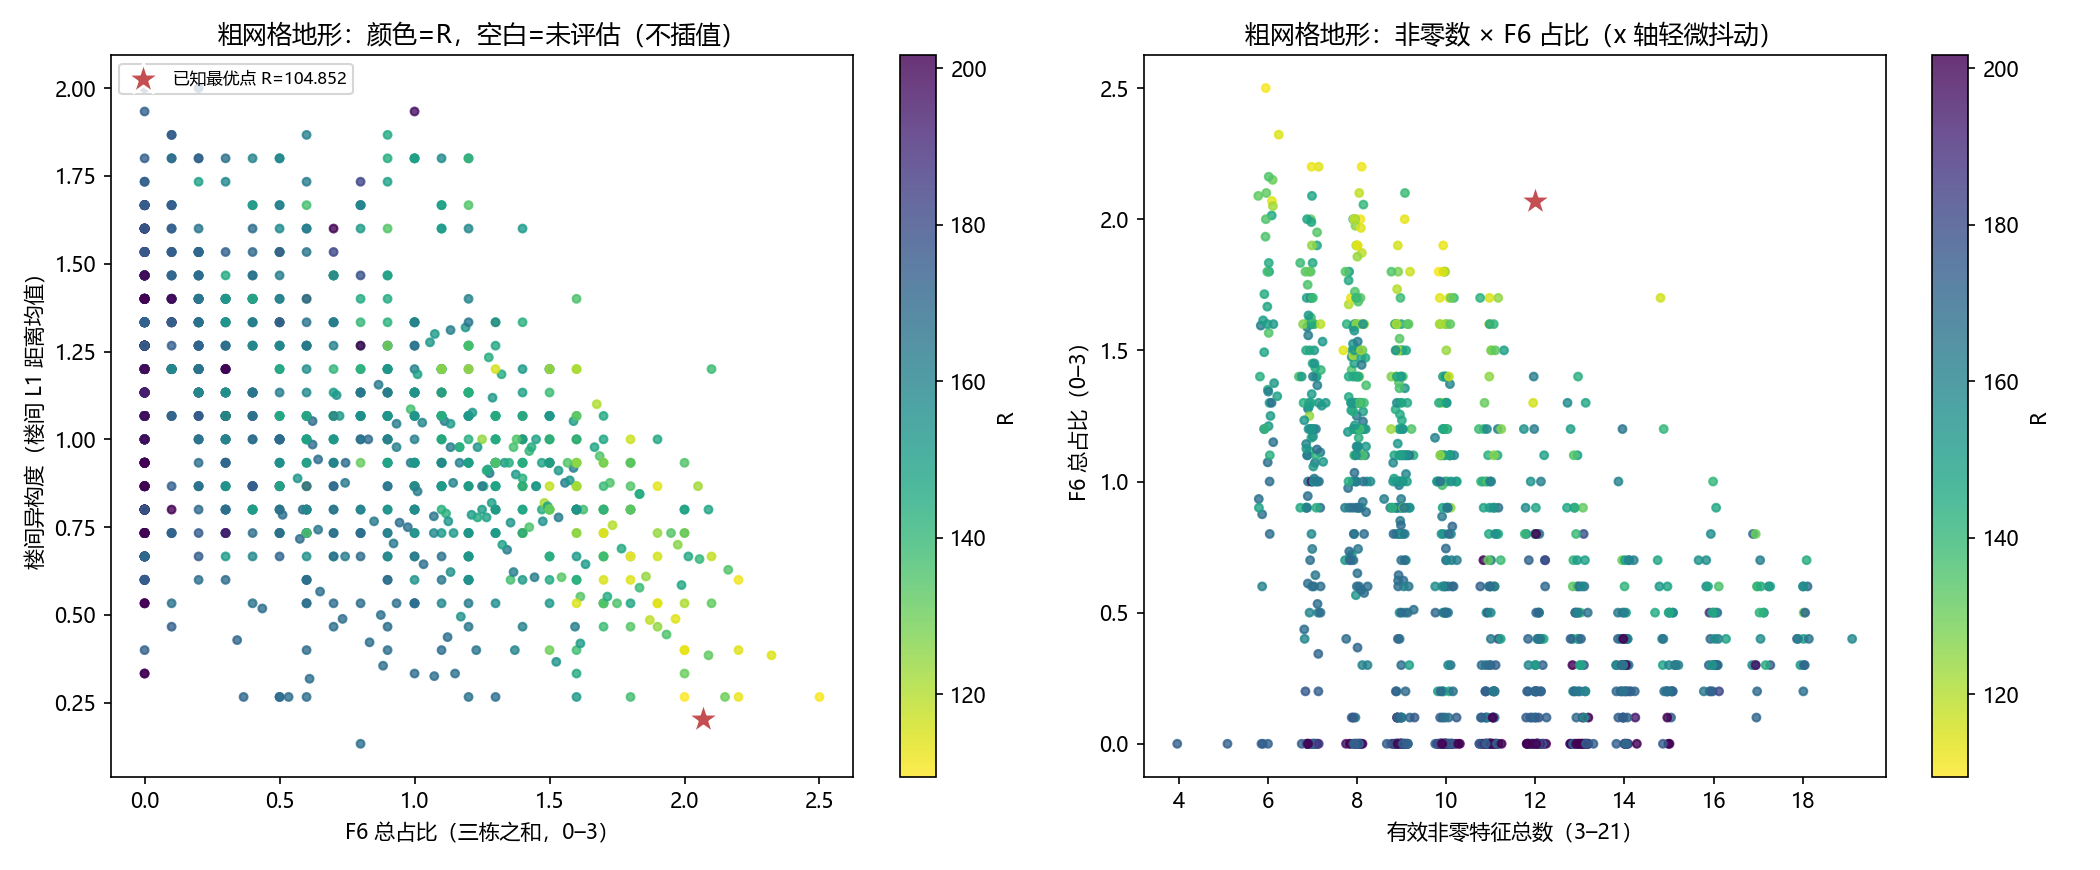

In [ ]:
from IPython.display import Image, display
display(Image(filename="figures/e12_e3_terrain_axes.png"))


## 6. 给 T15 的推荐参数

| 参数 | 推荐值 | 依据 | 类型 |
|---|---|---|---|
| 支持集规模 | 每栋 4 个非零，合计 12 | 6,568 点统计中 12 非零最优 | 实测 |
| 每栋必备槽位 | F5、F6 | 所有优质点均为 F5/F6 主导 | 实测 |
| 第 3/4 槽位 | F2、F3、F7 中按楼栋各取 2 个 | 最优配置楼1/楼2 取 F2+F7，楼3 取 F3+F7 | 实测 |
| F5+F6 占比 | 0.86–0.98 | 最优配置实测区间 | 实测 |
| `r` 初值 | 0.245–0.273 | 最优配置实测区间 | 实测 |
| 首批步长 | 0.05（覆盖 0.10–0.40） | 粗扫 0.2 只能到 109.5；0.05 兼顾覆盖与预算 | 建议 |
| 第二批步长 | 0.0125 | E4 在此量级收敛 | 实测 |
| 第三批步长 | 0.0025 | 再小无收益（平台宽 7×10⁻⁴） | 实测 |
| 零权重 | **精确 0.0** | 零面与极小正值面是不同地形（见 T20） | 实测 |
| 行和 | 归一化到 1 | 求解器要求每栋至少一个正权重 | 实测 |
| 单批上限 | 50 组 | `solver.exe` 单次调用上限 | 实测 |
| 停止条件 | 连续 2 批最好 R 未低于当前最优 0.05 | 平台内已无有效梯度 | 建议 |
| 预期收敛区间 | 104.85–105.5 | 全量实测 | 实测 |


## 7. 明确不推荐的做法

| 做法 | 实测证据 |
|---|---|
| 用 `1e-9` 代替零权重 | 纯 F6（其余为 0）R=117.80，其余填 `1e-9` 后 R=120.17，差 2.37，属于不同响应面 |
| 小步长精扫 | 0.0025 以下只有宽度 ≤0.0025 的单点凹口，单点收益 0.1–0.9，预算利用率极低 |
| 全 21 维随机搜索 | 盲随机 120 点最好 109.44，比结构先验差约 4.6 |
| 只扫单特征顶点 | 343 个顶点最好 120.299，无法进入 105 平台 |


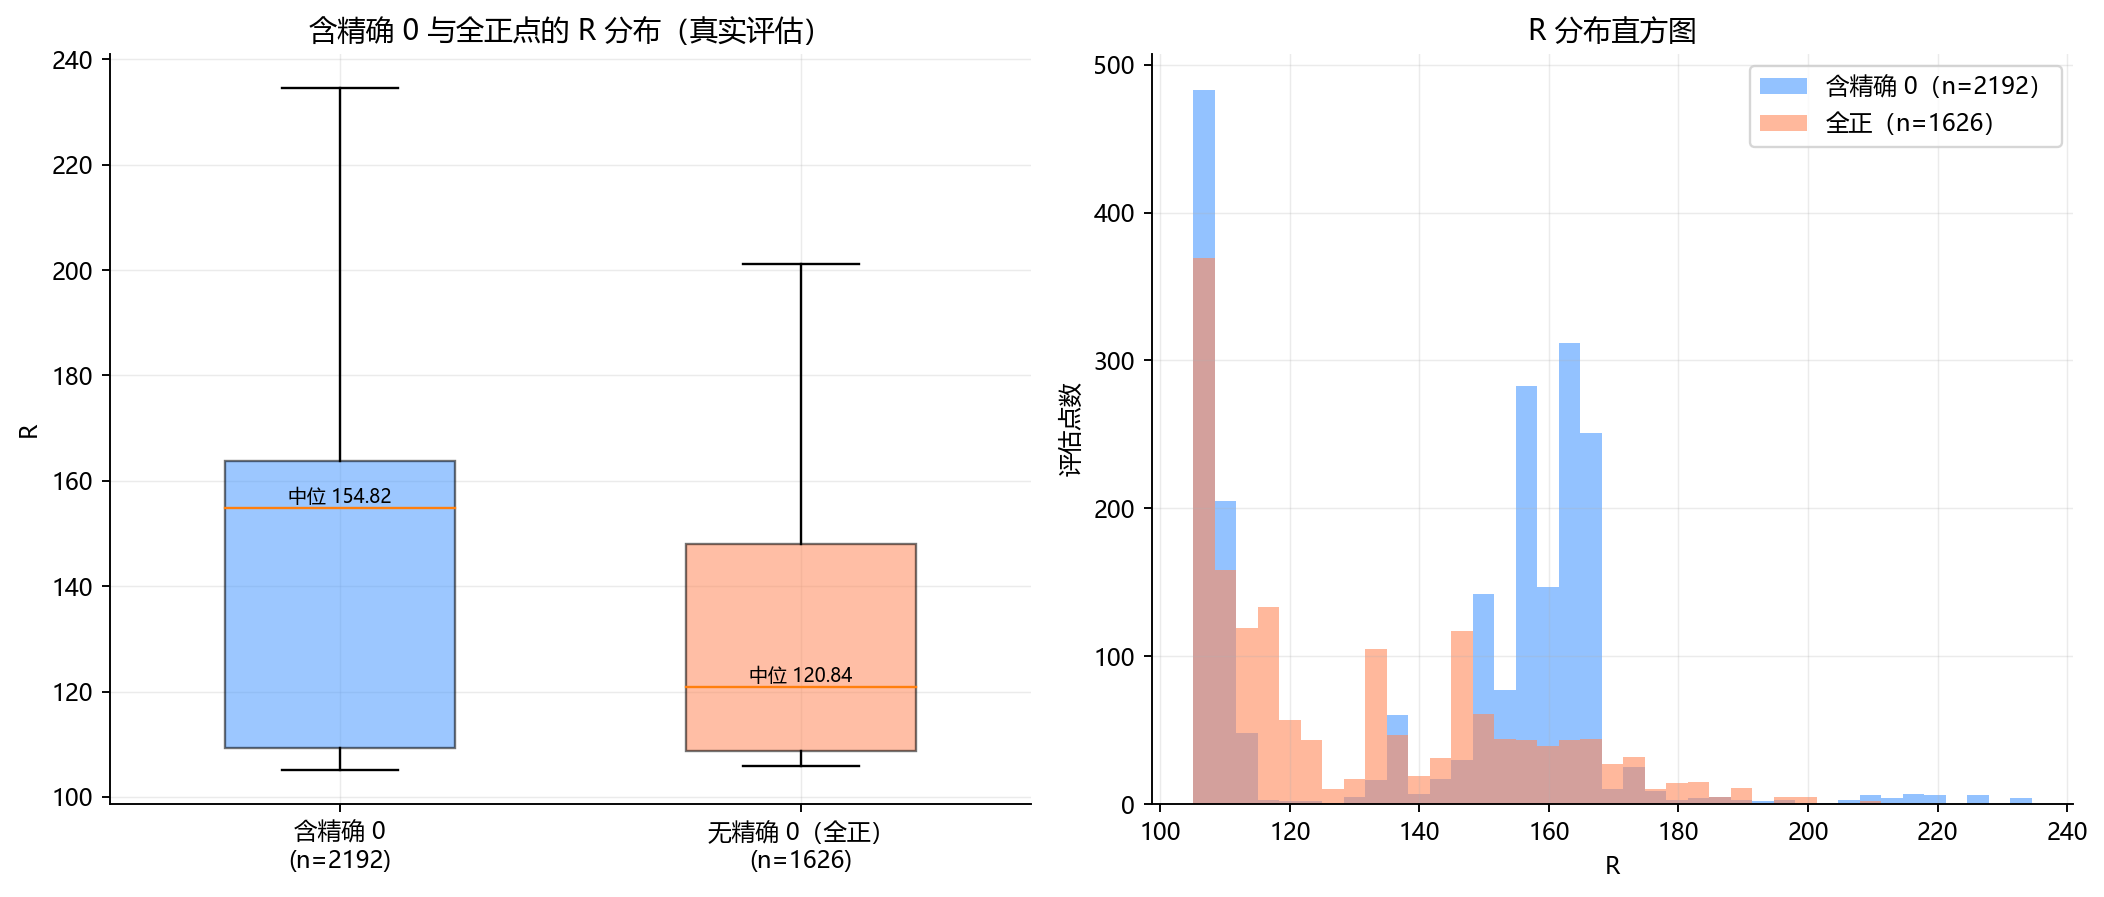

In [ ]:
from IPython.display import Image, display
display(Image(filename="figures/e3_zero_vs_positive.png"))


## 8. 证据与复现

| 内容 | 文件/编号 |
|---|---|
| 全量评估记录 | `evidence/eval_log.jsonl`（6,568 行，含 weights/R/phase/timestamp） |
| 最优配置 | `best_weights_phaseE5.json`（eval_id 6335） |
| 细扫与量化结论 | `evidence/E5_summary.json` |
| E4 细线扫描原始过程 | `evidence/E4_progress.json` |
| 支持集/同构对比 | `evidence/E3_summary.json` |
| 五非零族统计 | `evidence/E5_summary.json` → `family_stats` |

## 9. 待与上下游确认

- **T15（艾子齐）**：上述推荐参数以「一维 `r` 扫描」为前提；若在线提议策略改为多参数联合提议，需重新分配批次预算。
- **T12（刘润泽）**：模型选择可直接采用「F5/F6 主导 + 12 非零」这一结构先验，减少搜索空间。
- **T06/T07（张子木/武韵扬）**：本节的 R 值均来自本地 `solver.exe`，需与仓库评估器接口对拍确认同一口径。
- **decisions.md 定稿**：需要张子木确认写入位置与格式后再提交。
